# Part B — Notebook 01b: SimCLR Backbone -> YOLOv12s Fine-Tune @ ρ=0.20
**CSE 445 — Computer Vision | Group Assignment Part B | Task 1, Part (b)**

Loads the `simclr_backbone.pt` checkpoint produced by Notebook 01a, performs weight surgery into the
best Part-A architecture (YOLOv12s), fine-tunes at the fixed 20% label budget under the leakage-safe
partition, and evaluates against the random-init and COCO-pretrained baselines.

Attach as Kaggle inputs before running:
- The Part A dataset (same input used in 01a).
- The checkpoint dataset published from Notebook 01a (containing `simclr_backbone.pt`).
- (First run of this notebook computes the shared random-init / COCO baselines — publish `partB_baselines.csv` as a Kaggle dataset afterwards so 02b-04b can attach it and skip re-training them.)


## 0. Setup

In [1]:
!pip install -q ultralytics==8.3.* pyyaml scikit-learn

import os, sys, json, yaml, random, math, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import torch
from ultralytics import YOLO

print('Torch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 45.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA available: True


## 1. Config Cell

In [2]:
CONFIG = {
    'method_name': 'simclr',
    'architecture_base': 'yolo12s',
    'backbone_cutoff': 9,               # must match the *a notebook's cutoff exactly

    'seed': 42,                         # SAME seed as every *a notebook -> identical partition
    'test_frac': 0.10,
    'val_frac': 0.10,
    'label_fraction': 0.20,             # rho for Task 1 (fixed at 20% per Section 1)

    'dataset_path': Path('/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version'),
    'ssl_ckpt_path': Path('/kaggle/input/notebooks/salehrafi/notebook-01a-simclr-ssl-pretraining-diagnostics/simclr_backbone.pt'),  # TODO: fix dataset slug after publishing 01a's output
    'work_dir': Path('/kaggle/working'),
    'yolo_data_dir': Path('/kaggle/working/data_rho20'),

    'imgsz': 640,                       # detection resolution (Part A resolution — NOT the 224 SSL pretraining size)
    'batch': 16,
    'epochs': 50,                       # standard downstream fine-tune budget (Section 2)
    'lr0': 0.01,
    'optimizer': 'AdamW',
    'conf_thres': 0.25,
    'iou_thres': 0.7,                   # NMS IoU
    'workers': 2,
    'amp': True,

    'run_baselines': True,   # True only in the notebook that trains the shared baselines
    'baselines_csv_path': Path('/kaggle/input/partb-baselines/partB_baselines.csv'),  # TODO: fix slug once 01b publishes it
}

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
CONFIG


{'method_name': 'simclr',
 'architecture_base': 'yolo12s',
 'backbone_cutoff': 9,
 'seed': 42,
 'test_frac': 0.1,
 'val_frac': 0.1,
 'label_fraction': 0.2,
 'dataset_path': PosixPath('/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version'),
 'ssl_ckpt_path': PosixPath('/kaggle/input/notebooks/salehrafi/notebook-01a-simclr-ssl-pretraining-diagnostics/simclr_backbone.pt'),
 'work_dir': PosixPath('/kaggle/working'),
 'yolo_data_dir': PosixPath('/kaggle/working/data_rho20'),
 'imgsz': 640,
 'batch': 16,
 'epochs': 50,
 'lr0': 0.01,
 'optimizer': 'AdamW',
 'conf_thres': 0.25,
 'iou_thres': 0.7,
 'workers': 2,
 'amp': True,
 'run_baselines': True,
 'baselines_csv_path': PosixPath('/kaggle/input/partb-baselines/partB_baselines.csv')}

## 2. Locate the Part A Dataset (FLIR)

In [3]:
DATASET_PATH = CONFIG['dataset_path']

def locate_dataset_root(base: Path) -> Path:
    if (base / 'data.yaml').exists():
        return base
    matches = list(base.rglob('data.yaml'))
    if matches:
        return matches[0].parent
    raise FileNotFoundError(f'Could not locate data.yaml under {base}')

def locate_split_dir(root: Path, split: str, kind: str):
    candidates = [f'{split}/{kind}', f'{split}s/{kind}', f'{kind}/{split}', f'{split}']
    for c in candidates:
        p = root / c
        if p.exists() and any(p.iterdir()):
            return p
    for p in root.rglob('*'):
        if p.is_dir() and split in p.parts and kind in p.name.lower():
            return p
    return None

DATASET_ROOT = locate_dataset_root(DATASET_PATH)
DATA_YAML = DATASET_ROOT / 'data.yaml'

TRAIN_IMAGES = locate_split_dir(DATASET_ROOT, 'train', 'images')
TRAIN_LABELS = locate_split_dir(DATASET_ROOT, 'train', 'labels')
VALID_IMAGES = locate_split_dir(DATASET_ROOT, 'valid', 'images')
VALID_LABELS = locate_split_dir(DATASET_ROOT, 'valid', 'labels')
TEST_IMAGES  = locate_split_dir(DATASET_ROOT, 'test', 'images')
TEST_LABELS  = locate_split_dir(DATASET_ROOT, 'test', 'labels')

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

NUM_CLASSES = data_cfg.get('nc', 3)
CLASS_NAMES = data_cfg.get('names', ['car', 'dog', 'person'])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
print('Dataset root:', DATASET_ROOT, '| Classes:', NUM_CLASSES, CLASS_NAMES)


Dataset root: /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version | Classes: 3 ['car', 'dog', 'person']


## 3. Re-Derive the Leakage-Safe Partition (identical to every *a notebook)

Same seed, same pooling order as Notebook 01a -> byte-identical test/val/SSL-pool split. Unlike the *a
notebooks, labels are kept here (fine-tuning needs the boxes back for the 20% subset and for evaluation).

In [4]:
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def collect_pairs(img_dir, lbl_dir):
    if img_dir is None:
        return []
    pairs = []
    for img_path in sorted(img_dir.iterdir()):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        lbl_path = (lbl_dir / (img_path.stem + '.txt')) if lbl_dir else None
        pairs.append((img_path, lbl_path if (lbl_path and lbl_path.exists()) else None))
    return pairs

all_pairs = (collect_pairs(TRAIN_IMAGES, TRAIN_LABELS)
             + collect_pairs(VALID_IMAGES, VALID_LABELS)
             + collect_pairs(TEST_IMAGES, TEST_LABELS))

seen, dedup = set(), []
for img_path, lbl_path in all_pairs:
    if img_path.stem in seen:
        continue
    seen.add(img_path.stem)
    dedup.append((img_path, lbl_path))

dedup.sort(key=lambda t: t[0].name)
rng = random.Random(CONFIG['seed'])
rng.shuffle(dedup)

n_total = len(dedup)
n_test  = int(round(n_total * CONFIG['test_frac']))
n_val   = int(round(n_total * CONFIG['val_frac']))

test_pairs = dedup[:n_test]
val_pairs  = dedup[n_test:n_test + n_val]
ssl_pool_pairs = dedup[n_test + n_val:]   # 80% pool — Task 1b restores labels for a 20% sample of this

test_stems = {p.stem for p, _ in test_pairs}
val_stems  = {p.stem for p, _ in val_pairs}
pool_stems = {p.stem for p, _ in ssl_pool_pairs}
assert not (test_stems & pool_stems) and not (val_stems & pool_stems), 'LEAKAGE detected!'

print(f'Total: {n_total} | Test: {len(test_pairs)} | Val: {len(val_pairs)} | SSL pool: {len(ssl_pool_pairs)}')
print('Verified: test and val are disjoint from the SSL pool (same check as every *a notebook).')


Total: 26061 | Test: 2606 | Val: 2606 | SSL pool: 20849
Verified: test and val are disjoint from the SSL pool (same check as every *a notebook).


## 4. Build the ρ=0.20 Labelled Fine-Tuning Subset (seeded)

In [5]:
# Sample 20% of |D| from the SSL pool, seeded, with annotations restored.
# Only pool images that actually have a label file are eligible (an image with no .txt is
# either background-only or missing an annotation; excluding it keeps the fine-tune signal clean —
# note this choice in the report if any pool images lack labels).
pool_labelled = [(img, lbl) for img, lbl in ssl_pool_pairs if lbl is not None]
n_missing_labels = len(ssl_pool_pairs) - len(pool_labelled)
if n_missing_labels:
    print(f'WARNING: {n_missing_labels} SSL-pool images have no label file and are excluded from the labelled subset.')

n_rho = int(round(CONFIG['label_fraction'] * n_total))
subset_rng = random.Random(CONFIG['seed'])
subset_rng.shuffle(pool_labelled)  # independent shuffle instance, same seed -> reproducible, nesting-ready
train_subset = pool_labelled[:n_rho]

train_stems = {p.stem for p, _ in train_subset}
assert not (train_stems & test_stems) and not (train_stems & val_stems), 'LEAKAGE in fine-tuning subset!'
assert train_stems <= pool_stems, 'Fine-tuning subset must be drawn from the SSL pool only!'

print(f'rho=0.20 target size: {n_rho} | Labelled subset actually used: {len(train_subset)} images')
print('Verified: fine-tuning subset is disjoint from test/val and is a subset of the SSL pool.')


rho=0.20 target size: 5212 | Labelled subset actually used: 5212 images
Verified: fine-tuning subset is disjoint from test/val and is a subset of the SSL pool.


## 5. Materialise the Ultralytics Dataset Directory

In [6]:
def link_split(pairs, split_name):
    img_dir = CONFIG['yolo_data_dir'] / split_name / 'images'
    lbl_dir = CONFIG['yolo_data_dir'] / split_name / 'labels'
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for img_path, lbl_path in pairs:
        dst_img = img_dir / img_path.name
        if not dst_img.exists():
            os.symlink(img_path.resolve(), dst_img)
        if lbl_path is not None:
            dst_lbl = lbl_dir / lbl_path.name
            if not dst_lbl.exists():
                os.symlink(lbl_path.resolve(), dst_lbl)
    return img_dir

train_img_dir = link_split(train_subset, 'train')
val_img_dir   = link_split(val_pairs, 'val')
test_img_dir  = link_split(test_pairs, 'test')

rho_data_yaml = CONFIG['yolo_data_dir'] / 'data.yaml'
with open(rho_data_yaml, 'w') as f:
    yaml.safe_dump({
        'path': str(CONFIG['yolo_data_dir']),
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'nc': NUM_CLASSES,
        'names': CLASS_NAMES,
    }, f)

print('Wrote', rho_data_yaml)
print(f'train: {len(list(train_img_dir.iterdir()))} images | val: {len(list(val_img_dir.iterdir()))} images | test: {len(list(test_img_dir.iterdir()))} images')


Wrote /kaggle/working/data_rho20/data.yaml
train: 5212 images | val: 2606 images | test: 2606 images


## 6. Weight Surgery — Load the SSL Backbone Checkpoint

In [7]:
# weights_only=False: PyTorch >=2.6 defaults torch.load to weights_only=True, which refuses to
# unpickle the pathlib.Path objects stored inside the *a notebook's saved CONFIG dict. This
# checkpoint is our own trusted output (produced by Notebook 01a in this same pipeline), so
# it's safe to disable the restriction rather than allowlist individual classes.
ssl_ckpt = torch.load(CONFIG['ssl_ckpt_path'], map_location='cpu', weights_only=False)
ssl_state_dict = ssl_ckpt['state_dict']
print(f"Loaded checkpoint: method={ssl_ckpt.get('method')} | {len(ssl_state_dict)} backbone tensors "
      f"(layers 0-{CONFIG['backbone_cutoff']} of {CONFIG['architecture_base']})")
if 'integration_route' in ssl_ckpt:
    print('Integration route:', ssl_ckpt['integration_route'])

detector = YOLO(f"{CONFIG['architecture_base']}.yaml")
detector.model.nc = NUM_CLASSES

full_sd = detector.model.state_dict()
matched_keys = [k for k in ssl_state_dict if k in full_sd and full_sd[k].shape == ssl_state_dict[k].shape]
skipped_keys = [k for k in ssl_state_dict if k not in matched_keys]

load_result = detector.model.load_state_dict(ssl_state_dict, strict=False)

backbone_layer_ids = sorted({int(k.split('.')[1]) for k in matched_keys})
all_layer_ids = sorted({int(k.split('.')[1]) for k in full_sd if k.startswith('model.')})
random_init_layer_ids = sorted(set(all_layer_ids) - set(backbone_layer_ids))

print(f'\nMapping report:')
print(f'  Loaded from SSL checkpoint (backbone, layers {backbone_layer_ids[:1]}..{backbone_layer_ids[-1:]}): '
      f'{len(matched_keys)} tensors across {len(backbone_layer_ids)} layers')
print(f'  Remain randomly initialised (neck + detection head, layers {random_init_layer_ids[:3]}...): '
      f'{len(random_init_layer_ids)} layers')
if skipped_keys:
    print(f'  WARNING — {len(skipped_keys)} checkpoint tensors could not be matched (shape/key mismatch): {skipped_keys[:5]}...')
print(f'  torch missing_keys: {len(load_result.missing_keys)} | unexpected_keys: {len(load_result.unexpected_keys)}')

ssl_init_ckpt_path = CONFIG['work_dir'] / f"{CONFIG['method_name']}_init_{CONFIG['architecture_base']}.pt"
torch.save({'model': detector.model, 'train_args': {}}, ssl_init_ckpt_path)
print('\nSaved SSL-initialised detector to', ssl_init_ckpt_path)


Loaded checkpoint: method=simclr | 342 backbone tensors (layers 0-9 of yolo12s)

Mapping report:
  Loaded from SSL checkpoint (backbone, layers [0]..[8]): 342 tensors across 9 layers
  Remain randomly initialised (neck + detection head, layers [11, 14, 15]...): 7 layers
  torch missing_keys: 293 | unexpected_keys: 0

Saved SSL-initialised detector to /kaggle/working/simclr_init_yolo12s.pt


## 7. Baselines @ ρ=0.20 — Random-Init and COCO-Pretrained

Per Section 4.2(6): run once and reuse across all four downstream notebooks.

In [8]:
baseline_rows = []

if CONFIG['run_baselines']:
    # (a) Random initialisation
    random_model = YOLO(f"{CONFIG['architecture_base']}.yaml")
    random_model.model.nc = NUM_CLASSES
    random_results = random_model.train(
        data=str(rho_data_yaml), imgsz=CONFIG['imgsz'], batch=CONFIG['batch'], epochs=CONFIG['epochs'],
        optimizer=CONFIG['optimizer'], lr0=CONFIG['lr0'], seed=CONFIG['seed'], amp=CONFIG['amp'],
        workers=CONFIG['workers'], project=str(CONFIG['work_dir'] / 'runs'), name='baseline_random_init',
        exist_ok=True,
    )
    random_test = random_model.val(data=str(rho_data_yaml), split='test', imgsz=CONFIG['imgsz'],
                                    conf=CONFIG['conf_thres'], iou=CONFIG['iou_thres'])
    baseline_rows.append({
        'init': 'random', 'label_fraction': CONFIG['label_fraction'],
        'precision': float(random_test.results_dict.get('metrics/precision(B)', float('nan'))),
        'recall': float(random_test.results_dict.get('metrics/recall(B)', float('nan'))),
        'mAP50': float(random_test.results_dict.get('metrics/mAP50(B)', float('nan'))),
        'mAP50-95': float(random_test.results_dict.get('metrics/mAP50-95(B)', float('nan'))),
    })

    # (b) COCO-pretrained
    coco_model = YOLO(f"{CONFIG['architecture_base']}.pt")
    coco_model.model.nc = NUM_CLASSES
    coco_results = coco_model.train(
        data=str(rho_data_yaml), imgsz=CONFIG['imgsz'], batch=CONFIG['batch'], epochs=CONFIG['epochs'],
        optimizer=CONFIG['optimizer'], lr0=CONFIG['lr0'], seed=CONFIG['seed'], amp=CONFIG['amp'],
        workers=CONFIG['workers'], project=str(CONFIG['work_dir'] / 'runs'), name='baseline_coco',
        exist_ok=True,
    )
    coco_test = coco_model.val(data=str(rho_data_yaml), split='test', imgsz=CONFIG['imgsz'],
                                conf=CONFIG['conf_thres'], iou=CONFIG['iou_thres'])
    baseline_rows.append({
        'init': 'coco_pretrained', 'label_fraction': CONFIG['label_fraction'],
        'precision': float(coco_test.results_dict.get('metrics/precision(B)', float('nan'))),
        'recall': float(coco_test.results_dict.get('metrics/recall(B)', float('nan'))),
        'mAP50': float(coco_test.results_dict.get('metrics/mAP50(B)', float('nan'))),
        'mAP50-95': float(coco_test.results_dict.get('metrics/mAP50-95(B)', float('nan'))),
    })

    baselines_df = pd.DataFrame(baseline_rows)
    baselines_csv = CONFIG['work_dir'] / 'partB_baselines.csv'
    baselines_df.to_csv(baselines_csv, index=False)
    print('Saved', baselines_csv)
    print('Publish /kaggle/working as a Kaggle dataset (e.g. groupXX-partb-baselines) so 02b-04b can attach and skip re-training these.')
    display(baselines_df)
else:
    baselines_df = pd.read_csv(CONFIG['baselines_csv_path'])
    display(baselines_df)


New https://pypi.org/project/ultralytics/8.4.117 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_rho20/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.yaml, momentum=0.937, mosaic=1.0, multi_scale=False, name=baseline_random_init, nbs=

,init,label_fraction,precision,recall,mAP50,mAP50-95
0,random,0.2,0.749829,0.658626,0.700468,0.469298
1,coco_pretrained,0.2,0.745908,0.706071,0.728040,0.501057


## 8. Fine-Tune the SimCLR-Initialised Detector (50 epochs, fair-comparison protocol)

In [9]:
ssl_detector = YOLO(str(ssl_init_ckpt_path))

ft_results = ssl_detector.train(
    data=str(rho_data_yaml), imgsz=CONFIG['imgsz'], batch=CONFIG['batch'], epochs=CONFIG['epochs'],
    optimizer=CONFIG['optimizer'], lr0=CONFIG['lr0'], seed=CONFIG['seed'], amp=CONFIG['amp'],
    workers=CONFIG['workers'], project=str(CONFIG['work_dir'] / 'runs'), name='simclr_ft_rho20',
    exist_ok=True,
)
print('Fine-tuning complete.')


New https://pypi.org/project/ultralytics/8.4.117 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_rho20/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/simclr_init_yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=

## 9. Demo Inference (one validation image, before full evaluation)


image 1/1 /kaggle/working/data_rho20/val/images/Back20-11-08_11-16-20-71_00001_jpg.rf.47ea4d769a5d24dd15e163efde0ed53c.jpg: 480x640 2 persons, 63.2ms
Speed: 1.6ms preprocess, 63.2ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)


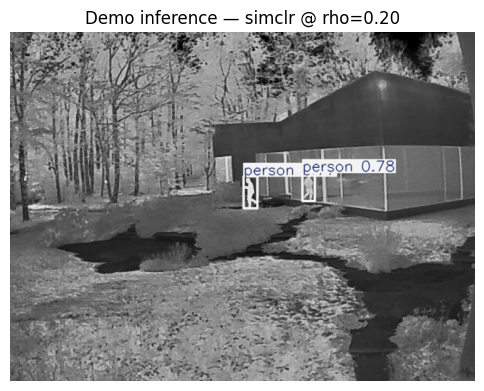

In [10]:
demo_img = sorted(val_img_dir.iterdir())[0]
demo_pred = ssl_detector.predict(source=str(demo_img), imgsz=CONFIG['imgsz'], conf=CONFIG['conf_thres'], save=False)
plt.figure(figsize=(6,6))
plt.imshow(demo_pred[0].plot()[:, :, ::-1])
plt.axis('off'); plt.title(f'Demo inference — {CONFIG["method_name"]} @ rho=0.20')
plt.show()


## 10. Evaluation — Precision, Recall, mAP50, mAP50-95, PR Curve, Qualitative Panel

Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 26.7±18.2 MB/s, size: 30.4 KB)
val: Scanning /kaggle/working/data_rho20/val/labels.cache... 2253 images, 353 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2606/2606 993.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 163/163 4.2it/s 38.4s
                   all       2606      14028      0.706      0.699      0.699      0.461
                   car       1483       7581      0.752      0.782      0.767      0.548
                   dog         83         87      0.632      0.517      0.575      0.353
                person       2060       6360      0.736      0.798      0.755      0.483
Speed: 0.7ms preprocess, 11.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val3
Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla 

,method,split,label_fraction,precision,recall,mAP50,mAP50-95
0,simclr,val,0.2,0.706468,0.698866,0.698951,0.461422
1,simclr,test,0.2,0.650176,0.749073,0.698148,0.469358



0: 480x640 1 person, 11.8ms
1: 480x640 1 person, 11.8ms
2: 480x640 1 person, 11.8ms
3: 480x640 2 persons, 11.8ms
4: 480x640 2 persons, 11.8ms
5: 480x640 2 persons, 11.8ms
6: 480x640 2 persons, 11.8ms
7: 480x640 1 person, 11.8ms
Speed: 1.9ms preprocess, 11.8ms inference, 0.8ms postprocess per image at shape (1, 3, 480, 640)


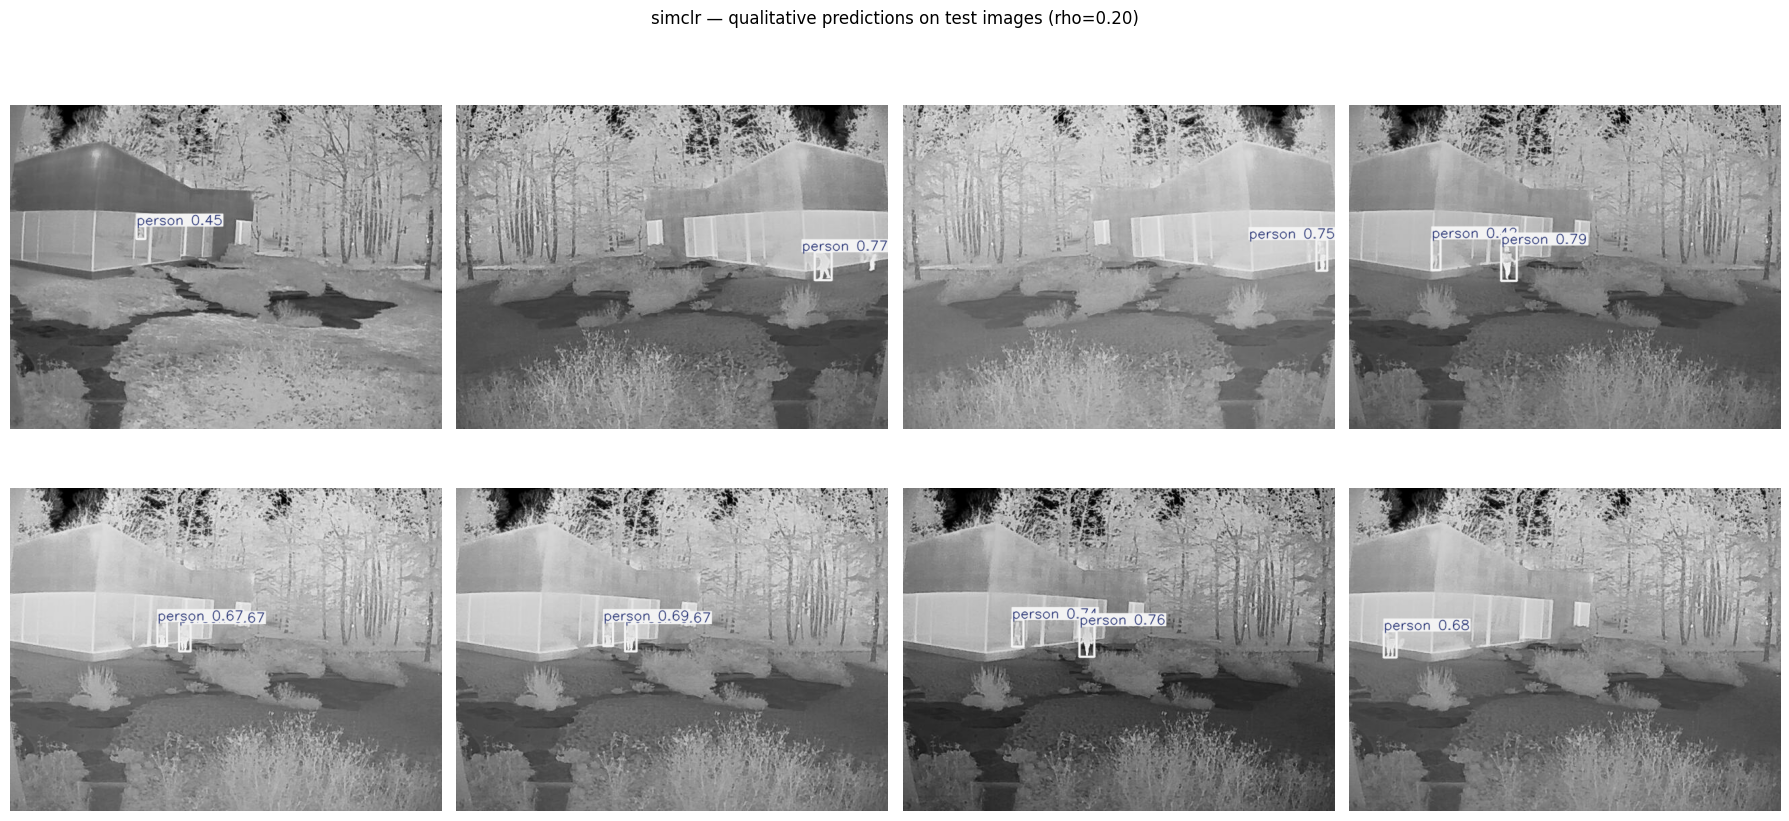

In [11]:
val_metrics = ssl_detector.val(data=str(rho_data_yaml), split='val', imgsz=CONFIG['imgsz'],
                                conf=CONFIG['conf_thres'], iou=CONFIG['iou_thres'])
test_metrics = ssl_detector.val(data=str(rho_data_yaml), split='test', imgsz=CONFIG['imgsz'],
                                 conf=CONFIG['conf_thres'], iou=CONFIG['iou_thres'])

def summarize(m, split):
    d = m.results_dict
    return {
        'method': CONFIG['method_name'], 'split': split, 'label_fraction': CONFIG['label_fraction'],
        'precision': float(d.get('metrics/precision(B)', float('nan'))),
        'recall': float(d.get('metrics/recall(B)', float('nan'))),
        'mAP50': float(d.get('metrics/mAP50(B)', float('nan'))),
        'mAP50-95': float(d.get('metrics/mAP50-95(B)', float('nan'))),
    }

results_rows = [summarize(val_metrics, 'val'), summarize(test_metrics, 'test')]
results_df = pd.DataFrame(results_rows)
display(results_df)

# PR curve (test split) — ultralytics saves curve data under the val run's save_dir
pr_curve_path = Path(test_metrics.save_dir) / 'PR_curve.png'
if pr_curve_path.exists():
    plt.figure(figsize=(6,6))
    plt.imshow(mpimg.imread(pr_curve_path)); plt.axis('off'); plt.title(f'{CONFIG["method_name"]} PR curve (test)')
    plt.show()

# Qualitative panel: 6-8 test predictions (successes and failures)
sample_test_imgs = sorted(test_img_dir.iterdir())[:8]
preds = ssl_detector.predict(source=[str(p) for p in sample_test_imgs], imgsz=CONFIG['imgsz'],
                              conf=CONFIG['conf_thres'], save=False)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, pred in zip(axes.flat, preds):
    ax.imshow(pred.plot()[:, :, ::-1]); ax.axis('off')
plt.suptitle(f'{CONFIG["method_name"]} — qualitative predictions on test images (rho=0.20)')
plt.tight_layout(); plt.show()


## 11. Append to the Shared Task-1 Results Table

In [12]:
summary_csv = CONFIG['work_dir'] / 'partB_task1_summary.csv'
row = results_df[results_df['split'] == 'test'].copy()
if summary_csv.exists():
    existing = pd.read_csv(summary_csv)
    existing = existing[existing['method'] != CONFIG['method_name']]  # replace any prior row for this method
    combined = pd.concat([existing, row], ignore_index=True)
else:
    combined = row
combined.to_csv(summary_csv, index=False)
print('Saved', summary_csv)
display(combined)
print('\nAfter all four *b notebooks have run, merge their partB_task1_summary.csv rows (or re-run this cell with '
      'all four outputs attached as inputs) to rank the four SSL methods by test mAP50-95 and pick the Task-2 winner.')


Saved /kaggle/working/partB_task1_summary.csv


,method,split,label_fraction,precision,recall,mAP50,mAP50-95
1,simclr,test,0.2,0.650176,0.749073,0.698148,0.469358



After all four *b notebooks have run, merge their partB_task1_summary.csv rows (or re-run this cell with all four outputs attached as inputs) to rank the four SSL methods by test mAP50-95 and pick the Task-2 winner.


## 11. Viva Prep — Notes to Fill In (SimCLR, Notebook 01b)

1. Why does SimCLR require negative pairs while BYOL does not? What failure mode do negatives prevent?
2. Derive the role of the temperature parameter tau in the NT-Xent loss. What happens at very small tau?
3. Why is the projection head discarded after pretraining instead of transferred to the detector?
4. Your batch size on a T4 is far smaller than in the original paper. How does this affect the contrastive objective, and what did you do about it?
5. Which augmentations matter most for SimCLR on your dataset's imagery, and which could be harmful for later detection fine-tuning?
6. How did your t-SNE/retrieval diagnostics change between an early and a final checkpoint?
